In [14]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 4420
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
DATA_PATH = Path('/Users/zhangxinxiang/Desktop/DS4420 Project/Charles_River_Data /daily_merged.csv')

In [15]:
df = pd.read_csv(DATA_PATH, parse_dates=['date']).sort_values('date').reset_index(drop=True)
use = df[df.date.between('1990-01-01','2025-12-31')].copy()

In [16]:
for k in range(1,8):
    for src,prefix in [('discharge_cfs_mean','flow'),('precip_in','precip'),('tmean_f','temp'),('snowfall_in','snow')]:
        use[f'{prefix}_lag_{k}'] = use[src].shift(k)
use = use.dropna(subset=[f'flow_lag_{k}' for k in range(1,8)]).copy()
flow_features = [f'flow_lag_{k}' for k in range(1,8)] + ['doy_sin','doy_cos']
weather_features = [f'{v}_lag_{k}' for v in ('precip','temp','snow') for k in range(1,8)]
all_features = flow_features + weather_features
train = use[use.date < '2017-01-01'].copy()
val = use[use.date.between('2017-01-01','2020-12-31')].copy()
test = use[use.date.between('2021-01-01','2025-12-31')].copy()
assert max(train.date) < min(val.date) < max(val.date) < min(test.date)

In [17]:
def prepare(features):
    med = train[features].median().fillna(0)
    Xtrain0 = train[features].fillna(med)
    scaler = StandardScaler().fit(Xtrain0)
    def x(part):
        return torch.tensor(scaler.transform(part[features].fillna(med)),dtype=torch.float32)
    def y(part):
        return torch.tensor(np.log1p(part['discharge_cfs_mean'].to_numpy()), dtype=torch.float32).reshape(-1,1)
    return x(train),y(train),x(val),y(val),x(test),scaler,med

class MLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features,32),nn.ReLU(),
                                 nn.Linear(32,16),nn.ReLU(),nn.Linear(16,1))
    def forward(self,x): return self.net(x)

def train_model(features, max_epochs=140, patience=16):
    torch.manual_seed(SEED)
    Xt,yt,Xv,yv,Xe,scaler,med = prepare(features)
    model = MLP(len(features))
    opt = torch.optim.Adam(model.parameters(),lr=0.003,weight_decay=0.0001)
    criterion=nn.MSELoss()
    best=float('inf'); wait=0; best_state=None; losses=[]
    for epoch in range(max_epochs):
        model.train()
        ix = torch.randperm(len(Xt))
        for b in ix.split(512):
            opt.zero_grad()
            loss=criterion(model(Xt[b]),yt[b])
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            tr=criterion(model(Xt),yt).item()
            va=criterion(model(Xv),yv).item()
        losses.append((tr,va))
        if va < best-1e-5:
            best=va; wait=0
            best_state={k:v.detach().clone() for k,v in model.state_dict().items()}
        else:
            wait+=1
            if wait>=patience:break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred=np.expm1(model(Xe).numpy().reshape(-1))
    pred=np.maximum(pred,0)
    return dict(model=model,pred=pred,losses=np.asarray(losses),scaler=scaler,medians=med,features=features)

flow_only=train_model(flow_features)
flow_weather=train_model(all_features)


In [18]:
y_true=test['discharge_cfs_mean'].to_numpy()
preds={
    'Persistence (yesterday)':test['flow_lag_1'].to_numpy(),
    'MLP: flow + season':flow_only['pred'],
    'MLP: flow + weather + season':flow_weather['pred']
}
rows=[]
for name,pred in preds.items():
    rows.append({'Model':name,
                 'MAE (cfs)':mean_absolute_error(y_true,pred),
                 'RMSE (cfs)':np.sqrt(mean_squared_error(y_true,pred)),
                 'R²':r2_score(y_true,pred)})
results=pd.DataFrame(rows).sort_values('MAE (cfs)').reset_index(drop=True)
print(results.round(3).to_string(index=False))


                       Model  MAE (cfs)  RMSE (cfs)    R²
     Persistence (yesterday)     27.691      57.304 0.957
MLP: flow + weather + season     31.207      60.957 0.951
          MLP: flow + season     32.483      63.780 0.946


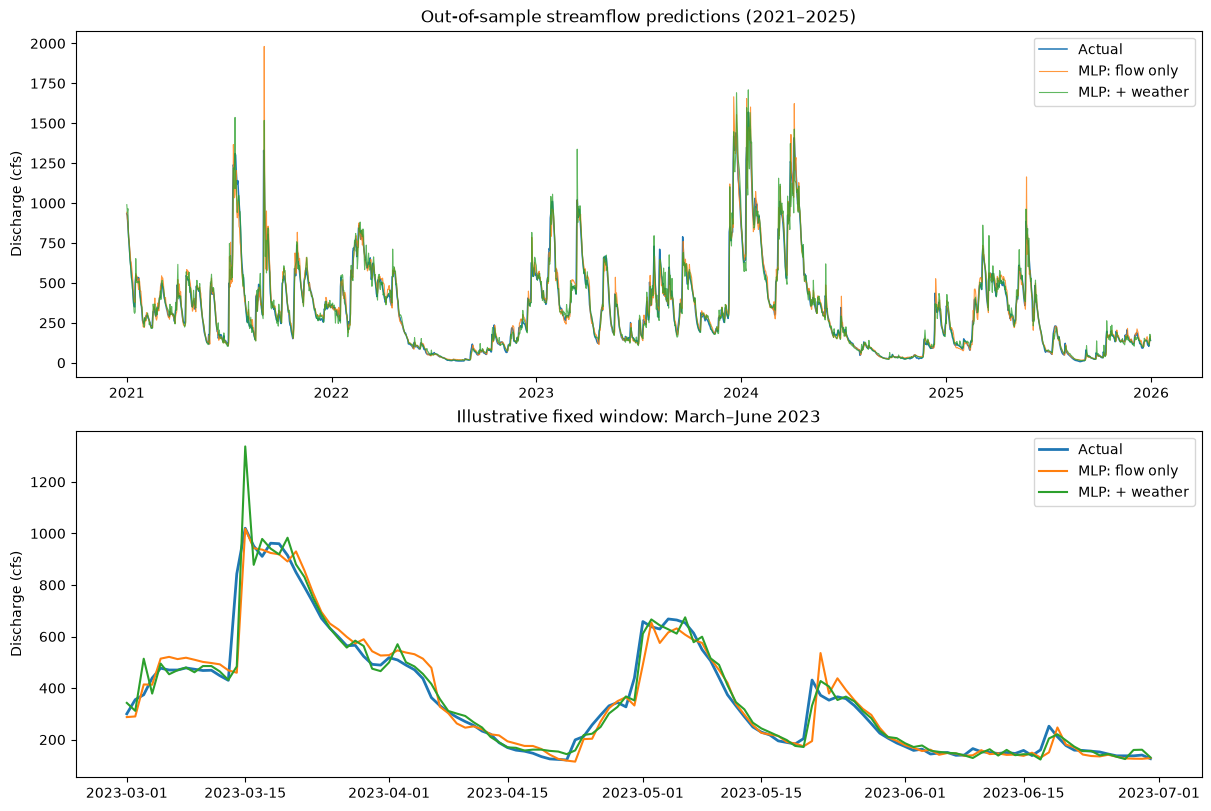

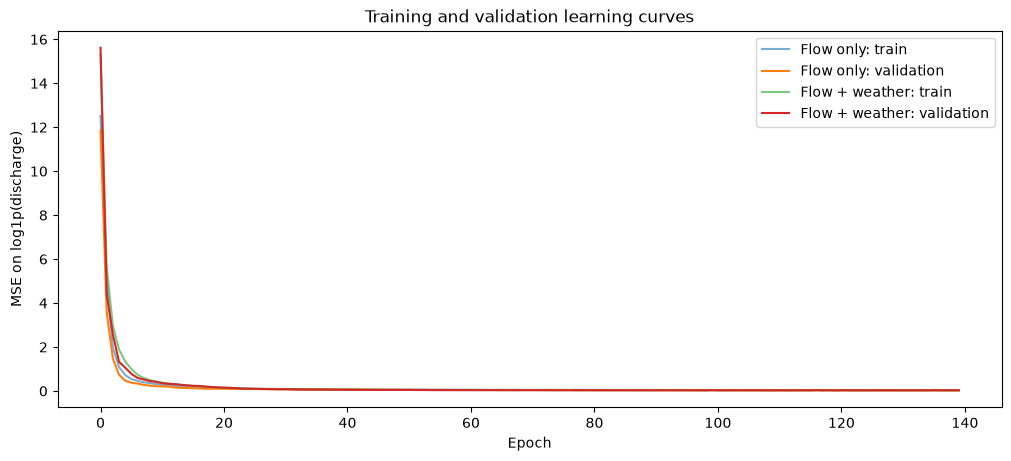

In [19]:
out_dir=Path('mlp_outputs'); out_dir.mkdir(exist_ok=True)
fig,axs=plt.subplots(2,1,figsize=(12,8),layout='constrained')
axs[0].plot(test.date,y_true,label='Actual',linewidth=1.1)
axs[0].plot(test.date,flow_only['pred'],label='MLP: flow only',alpha=.8,linewidth=.8)
axs[0].plot(test.date,flow_weather['pred'],label='MLP: + weather',alpha=.75,linewidth=.8)
axs[0].set_title('Out-of-sample streamflow predictions (2021–2025)')
axs[0].set_ylabel('Discharge (cfs)');axs[0].legend()
mask=test.date.between('2023-03-01','2023-06-30').to_numpy()
axs[1].plot(test.date[mask],y_true[mask],label='Actual',linewidth=2)
axs[1].plot(test.date[mask],flow_only['pred'][mask],label='MLP: flow only')
axs[1].plot(test.date[mask],flow_weather['pred'][mask],label='MLP: + weather')
axs[1].set_title('Illustrative fixed window: March–June 2023')
axs[1].set_ylabel('Discharge (cfs)');axs[1].legend()
fig.savefig(out_dir/'mlp_predictions.png',dpi=170,bbox_inches='tight')
plt.show()

fig,ax=plt.subplots(figsize=(10,4.5),layout='constrained')
for name,obj in [('Flow only',flow_only),('Flow + weather',flow_weather)]:
    ax.plot(obj['losses'][:,0],label=f'{name}: train',alpha=.6)
    ax.plot(obj['losses'][:,1],label=f'{name}: validation')
ax.set_xlabel('Epoch');ax.set_ylabel('MSE on log1p(discharge)')
ax.set_title('Training and validation learning curves')
ax.legend()
fig.savefig(out_dir/'mlp_learning_curves.png',dpi=170,bbox_inches='tight')
plt.show()


## 6. High-flow diagnostic (optional)

Define *high-flow* as exceeding the **95th percentile of training-period daily discharge**. This is a statistical threshold, **not** an official flood-stage classification. Check whether predictions meet the threshold on true high-flow days; a low overall MAE can mask poor peak forecasting.

In [20]:
threshold=float(train['discharge_cfs_mean'].quantile(.95))
actual_high=y_true>=threshold
hi_rows=[]
for name,pred in preds.items():
    predicted_high=pred>=threshold
    tp=int((predicted_high & actual_high).sum())
    fp=int((predicted_high & ~actual_high).sum())
    fn=int((~predicted_high & actual_high).sum())
    hi_rows.append({'Model':name,'High-day MAE (cfs)':mean_absolute_error(y_true[actual_high],pred[actual_high]),
                    'Recall':tp/(tp+fn) if tp+fn else np.nan,
                    'Precision':tp/(tp+fp) if tp+fp else np.nan,
                    'Predicted high days':int(predicted_high.sum())})
high_results=pd.DataFrame(hi_rows)
print('Training-only high-flow threshold (95th pct):',round(threshold,2),'cfs')
print('True high days in test:',int(actual_high.sum()))
print(high_results.round(3).to_string(index=False))


Training-only high-flow threshold (95th pct): 886.0 cfs
True high days in test: 97
                       Model  High-day MAE (cfs)  Recall  Precision  Predicted high days
     Persistence (yesterday)              96.670   0.887      0.878                   98
          MLP: flow + season             117.199   0.825      0.899                   89
MLP: flow + weather + season             128.713   0.876      0.895                   95
